# Cement Proton-NMR Relaxation Spectral Evolution


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`echo_time`，shape `(1, 256)`，dtype `<f8`：Native echo-center times in seconds, shared by all acquisitions.；`echo`，shape `(1, 120, 256)`，dtype `<c16`：Measured real+i imaginary magnetization amplitude in instrument arbitrary units; axes (batch, acquisition, echo).。未知量为120次水泥NMR的非负弛豫时间谱与拟合回波。

获取模型：指数衰减核将离散T2幅度分布映射为复数/相位校正回波信号。

如何恢复：src.main.run → src.solvers.reconstruct/solve：相位校正、指数kernel及增广NNLS ridge逆Laplace谱求解。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell10两组图显示全部谱、回波一致性、均值反演和逐次反演比较及正则化实验。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留1个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。弛豫谱非空间分布；不能称为空间成像真值。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

Recover all 120 nonnegative proton relaxation spectra of cement paste from measured complex echo trains whose exponential kernels strongly blur neighboring water environments.

This maintainer notebook actively reconstructs the complete bound observations with local numerical modules. It distinguishes the independently reproduced original method from fresh cleaned results. There is no cache-preview path. The paper describes the selected model; the exact bound dataset and modern port have separate provenance.


## 2. Data

The input is `data/raw_data.npz`; all arrays include batch size one.

| Key | Shape | Dtype | Description |
| --- | --- | --- | --- |
| `echo_time` | `(1, 256)` | `float64` | Native echo-center times in seconds, shared by all acquisitions. |
| `echo` | `(1, 120, 256)` | `complex128` | Measured real+i imaginary magnetization amplitude in instrument arbitrary units; axes (batch, acquisition, echo). |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
| --- | --- | --- | --- |
| Echo times | Stored individually, 256 values | s | Native irregular logarithmic echo schedule |
| Quadrature convention | real + i imaginary | a.u. | Coherent transverse magnetization signal |
| Phase estimate | Mean of four angles at zero-based echoes 1,2,3,4 | rad | Use atan(Im/Re), add π when Re<0 |
| First echo treatment | Discard zero-based echo 0 after phasing | 1 | Preserves author treatment of initial echo artifact |
| Relaxation grid | 10^(-5+5j/254), j=0..254 | s | Discrete exponential model required for output interpretation |
| Scans | 120 | 1 | Complete OPC example, filename-sorted acquisition order |
| Offset model | 0 | a.u. | Complex-acquisition branch has no magnitude offset |
| Noise variance | Not supplied | a.u.² | No known Gaussian uncertainty is asserted |
| Boundary | No contribution outside relaxation grid | 1 | Finite-grid inversion assumption |


## 3. Physics

### Observation and inverse problem

For acquisition index s and echo time t in seconds, the phase-corrected signal obeys

$$
y_s(t)=\sum_{j=0}^{254} a_{sj}\exp(-t/T_j)+\epsilon_s(t),\qquad a_{sj}\geq0.
$$

Here a is discrete echo amplitude in instrument arbitrary units, T is transverse relaxation time (s), y is the real coherent signal after constant quadrature-phase correction, and epsilon is measurement/model error. T[j]=10^(-5+5j/254) s. The amplitudes are discrete bin coefficients, not a density per second or per logarithmic interval. No constant offset is included in the complex-acquisition model.

Recover the full 120-acquisition series. Each stored trace has 256 measured complex echoes; discard only the first echo after estimating each acquisition's phase from echoes 1 through 4. The inverse problem is ill-conditioned even when the exponential model is exact. Acquisition order is known; hydration ages, pore radii and specimen recipe are not inferred from missing metadata.


## 4. Method

### Implemented mathematics and numerical conventions

All 120 author OPC files are used in increasing filename order; no synthetic generator is shipped. Read original time column in milliseconds and convert by the exact stored factor 1e-3 to seconds; retain float64 quadrature components in complex128. For each scan, estimate theta as mean over zero-based echoes 1..4 of atan(Im/Re)+π if Re<0. Rotate real=cos(theta)Re+sin(theta)Im. Then drop echo zero, preserving the other 255 acquisition times.

The exponential kernel E_ij=exp(-t_i/T_j) uses T=logspace(-5,0,255) s. Each scan solves min_(a>=0) ||Ea-y||²+alpha||a||², alpha=1e-4, without sample-count normalization and without one-half factors. Construct [E;sqrt(alpha)I] and [y;0], then call the general-purpose active-set scipy.optimize.nnls. This exactly preserves the selected upstream complex-signal branch, which has no offset. There is no logarithmic quadrature weight because a_j denotes a discrete amplitude, not a continuous density. No custom line search or separate initialization is introduced; NNLS initialization and numerical stopping are its standard active-set rules.

The standard CLI reconstructs every acquisition independently and preserves absolute instrument amplitude. The notebook additionally averages already phase-corrected signals, solves the same augmented NNLS once, and contrasts that with the mean of the individually recovered amplitudes. The nonnegativity constraint makes these different operations; neither is substituted for the full-series submission. A separate original upstream average inversion was frozen before implementing this comparison. Alpha sweeps 1e-6,1e-4,1e-2 actively recompute all scans. Integrated amplitude and amplitude-weighted geometric mean T2 are diagnostics, not calibrated porosity or pore size.

The 2024 paper establishes the published nonnegative relaxed ILT use and cites this source. The bound 2018 OPC example has its own provenance; no 2024 acquisition recipe, carrier frequency or instrument setting is silently assigned to those traces. Forward inversion needs actual stored echo times and the coherent signal model, not an unavailable carrier frequency.


## 5. Results

The preserved code below contains the active reconstruction and comparison path. Its saved outputs are retained from the earlier execution. This documentation edit does not rerun that path; displayed measurements remain evidence of the stored execution rather than a new numerical run.


In [1]:
%matplotlib inline
from pathlib import Path
import os,sys,time,json,subprocess,hashlib
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),Path.cwd().parent] if (p/'src').is_dir())
os.chdir(ROOT)
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.main import run
from src.visualization import make_figures,relative_error
data=load_data()
display(Markdown('| Observation | Internal shape | Dtype |\n| --- | --- | --- |\n'+'\n'.join(f'| {k} | {v.shape} | {v.dtype} |' for k,v in data.items())))

| Observation | Internal shape | Dtype |
| --- | --- | --- |
| echo_time | (256,) | float64 |
| echo | (120, 256) | complex128 |

### Fresh full reconstruction

The standard local path below computes every required output quantity from the bound public measurements and writes the declared submission. Runtime includes the complete reconstruction. Evaluation is a separate subprocess using the standalone Judge.


In [2]:
start=time.perf_counter()
fresh=run()
solver_runtime_s=time.perf_counter()-start
judge_process=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True,encoding='utf8',env=dict(os.environ,PYTHONIOENCODING='utf-8'))
assert judge_process.returncode==0,judge_process.stderr
judge_report=json.loads(Path('output/judge_report.json').read_text(encoding='utf8'))
assert judge_report['status']=='pass'
with np.load('evaluation/baseline_reference.npz',allow_pickle=False) as f:reference={k:f[k].copy() for k in f.files}
agreement={key:relative_error(fresh[key],reference[key]) for key in fresh}
print(json.dumps({'identity':'fresh cleaned full reconstruction','solver_runtime_s':solver_runtime_s,'upstream_relative_errors':agreement,'standalone_judge':judge_report},indent=2,allow_nan=False))

{
  "identity": "fresh cleaned full reconstruction",
  "solver_runtime_s": 0.41927559999749064,
  "upstream_relative_errors": {
    "reconstruction": 0.0,
    "fitted_echo": 1.9925444661101046e-16
  },
  "standalone_judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "reconstruction_relative_error": 0.0,
      "fitted_echo_relative_error": 1.9925444661101046e-16
    },
    "thresholds": {
      "reconstruction_relative_error": {
        "comparison": "<=",
        "boundary": 1e-05
      },
      "fitted_echo_relative_error": {
        "comparison": "<=",
        "boundary": 1e-05
      }
    },
    "errors": []
  }
}


### Scientific comparisons and recomputed experiments

The reconstruction figure includes measured signal consistency and independently reproduced upstream comparison. The robustness figure recomputes its model/regularization and acquisition/calibration changes. Original arrays are comparison inputs only; every curve labeled fresh is computed here. Exact numerical trace arrays are returned for the separately archived figure exports.


In [3]:
experiment_start=time.perf_counter()
figures,plot_trace,experiment_metrics=make_figures(data,fresh,reference)
plt.close('all')
experiment_runtime_s=time.perf_counter()-experiment_start
measurement={'identity':'fresh cleaned notebook reconstruction and actively recomputed comparisons','raw_data_sha256':hashlib.sha256(Path('data/raw_data.npz').read_bytes()).hexdigest(),'solver_runtime_s':solver_runtime_s,'experiments_runtime_s':experiment_runtime_s,'upstream_relative_errors':agreement,'scientific_measurements':experiment_metrics,'judge':judge_report,'historical_paper_numbers_used':False}
Path('notebooks/reference_outputs/fresh_measurements.json').write_text(json.dumps(measurement,indent=2,allow_nan=False)+'\n',encoding='utf8')
print(json.dumps(experiment_metrics,indent=2,allow_nan=False))

{
  "upstream_relative_error": 0.0,
  "observation_relative_error": 0.031206193440131567,
  "averaged_vs_mean_individual_relative_error": 0.2286724439040547,
  "alpha_relative_residual_amplitude_norm": [
    [
      1e-06,
      0.03118965219650046,
      466.08550729242114
    ],
    [
      0.0001,
      0.031206193440131567,
      207.74564012842237
    ],
    [
      0.01,
      0.03132119385727345,
      156.18428836517697
    ]
  ]
}


### Reconstruction

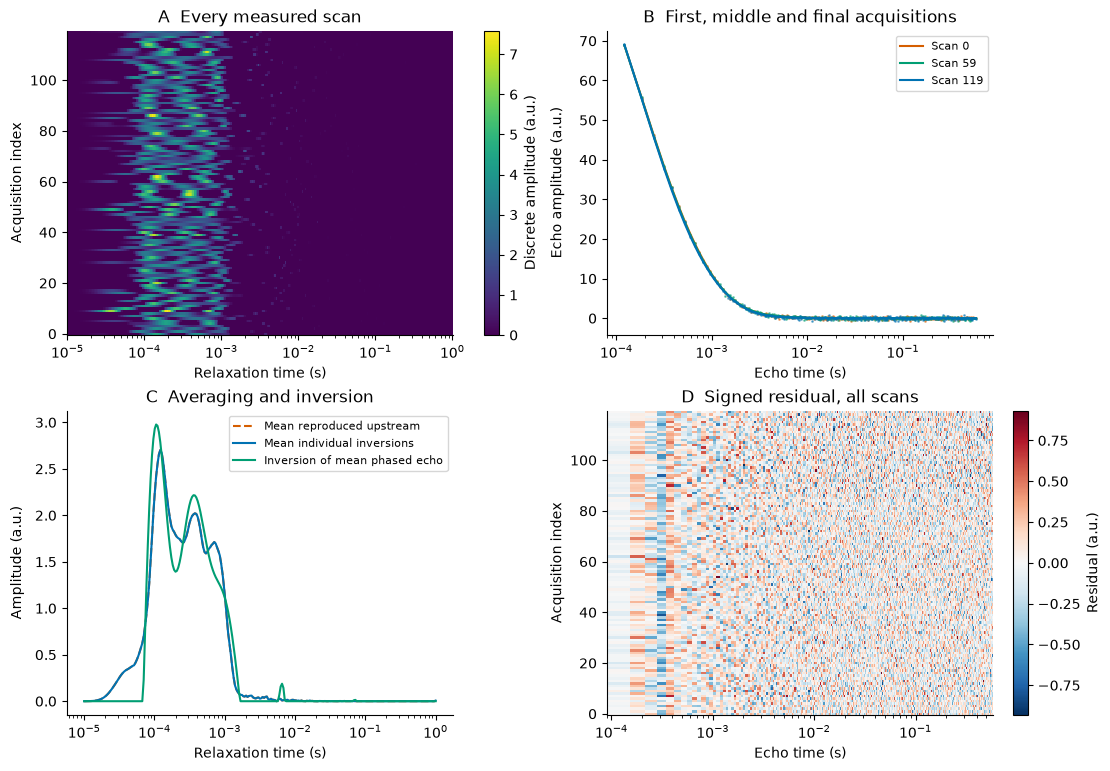

### Robustness

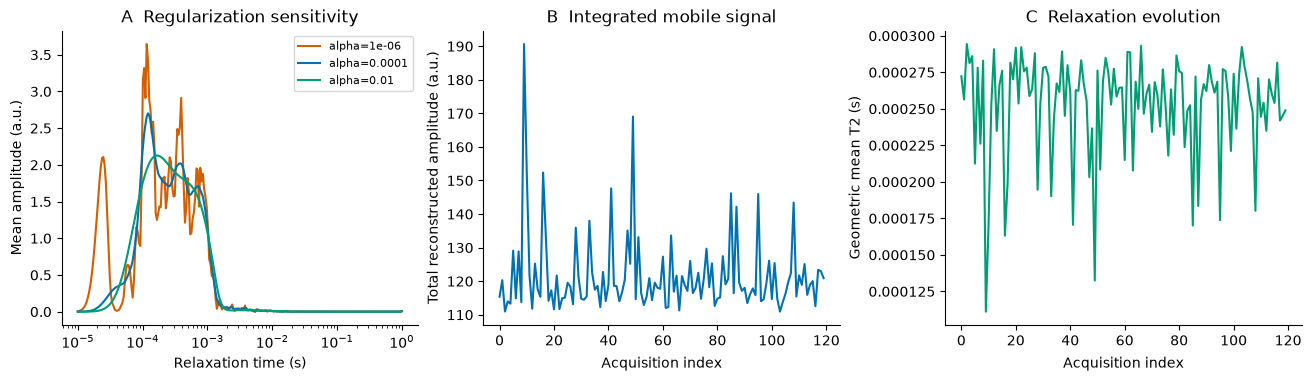

In [4]:
for figure_name,figure in figures.items():
    display(Markdown('### '+figure_name.replace('_',' ').title()))
    display(figure)
    plt.close(figure)

### Sources

Georget et al., Reconciliation of pore structure characterization methods: The simple case of PC-limestone cement pastes, Cement and Concrete Research 184 (2024), 107624. https://doi.org/10.1016/j.cemconres.2024.107624

The bound observation is the independent author-deposited OPC example series, not claimed to be a particular specimen or result figure from this paper.


## 6. Conclusion

### Interpretation and limitations

All 120 independent acquisitions are reconstructed. The mean of individual constrained inversions differs from inversion of the coherently averaged signal; neither result is silently substituted. Regularization changes peak width and weak populations. Acquisition index is the only validated ordering coordinate, so these figures do not invent hydration age or physical pore size. Total amplitude and geometric mean T2 are model diagnostics in the original instrument scale.

Agreement with the standard method establishes implementation fidelity. Independent mathematical tests check operators and signs, while measured residuals and sensitivity studies bound physical interpretation. No reconstruction is relabeled as ground truth.

The fitted amplitudes are discrete relaxation-bin strengths in instrument units. Comparing the mean of 120 constrained inversions with inversion of the coherently averaged signal tests nonlinearity of nonnegative estimation; neither diagnostic supplies hydration ages or pore radii.
